# Notebook 04: Arrhenius Reaction Kinetics of Protein Denaturation

In Notebooks 01–03, cooking stages were approximated by instantaneous temperature thresholds ($63\,^\circ\text{C}$ for egg white, $65\,^\circ\text{C}$ for soft yolk, $70\,^\circ\text{C}$ for hard yolk). In physical chemistry and food science, however, protein coagulation is a **time- and temperature-dependent irreversible rate process** governed by **Arrhenius reaction kinetics**:

$$\frac{d\alpha}{dt} = k(T)\,(1 - \alpha), \qquad k(T) = A \exp\!\left(-\frac{E_a}{R\,T}\right)$$

where:
- $\alpha(\mathbf{x}, t) \in [0, 1]$ is the local **degree of protein denaturation** ($0 =$ raw/native, $1 =$ fully coagulated),
- $E_a$ is the activation energy $[\text{J/mol}]$,
- $A$ is the pre-exponential frequency factor $[\text{s}^{-1}]$,
- $R = 8.314\,\text{J/(mol}\cdot\text{K)}$ is the universal gas constant.

Integrating along the nodal temperature trajectory $T(\mathbf{x}, t)$ gives the exact cumulative conversion:

$$\alpha(\mathbf{x}, t) = 1 - \exp\!\left(-\int_0^t A \exp\!\left(-\frac{E_a}{R\,T(\mathbf{x}, \tau)}\right) d\tau\right)$$

This notebook explores four fundamental culinary phenomena that simple temperature thresholds cannot explain:
1. **The Arrhenius Kinetic Crossover**: Why yolk thickens faster than white below $64.5\,^\circ\text{C}$, whereas white sets rapidly above $65\,^\circ\text{C}$.
2. **Spatiotemporal Coagulation $\alpha(r, z, t)$ & the Soft-Boiled Perfection Index**: Quantifying the lag between reaching $63\,^\circ\text{C}$ and actual protein setting, and finding the exact boil duration (~7.9 min) that maximizes set white ($94.2\%$) with runny yolk ($4.4\%$).
3. **Carryover Cooking vs. Ice-Bath Quenching**: How thermal inertia continues cooking the yolk on the counter after removal from boiling water (+73.7% yolk coagulation!), and how an ice bath halts the Arrhenius integral.
4. **Low-Temperature Long-Time Cooking (Onsen Tamago at $63.5\,^\circ\text{C}$)**: How a $63.5\,^\circ\text{C}$ water bath coagulates the yolk into custard ($80.4\%$) over 45 minutes without ever reaching the $65\,^\circ\text{C}$ threshold.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from egg_fem import (
    HeatSolver,
    H_BOILING_SHELL,
    T_BOILING,
    T_ROOM,
    WHITE_DENATURATION_K,
    YOLK_DENATURATION_K,
    WHITE_KINETICS,
    YOLK_KINETICS,
    compute_denaturation_history,
    create_egg_mesh,
    egg_white_denaturation_properties,
    egg_yolk_denaturation_properties,
)

plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

print(f"Egg White Kinetics: E_a = {WHITE_KINETICS.E_a / 1e3:.0f} kJ/mol, "
      f"t_1/2(63 °C) = {WHITE_KINETICS.half_life(273.15 + 63):.0f} s")
print(f"Egg Yolk Kinetics:  E_a = {YOLK_KINETICS.E_a / 1e3:.0f} kJ/mol, "
      f"t_1/2(65 °C) = {YOLK_KINETICS.half_life(273.15 + 65):.0f} s")

Egg White Kinetics: E_a = 480 kJ/mol, t_1/2(63 °C) = 900 s
Egg Yolk Kinetics:  E_a = 250 kJ/mol, t_1/2(65 °C) = 360 s


## 1. Arrhenius Rate Curves & the Kinetic Crossover

Egg white proteins (primarily ovalbumin and ovotransferrin) have a much higher activation energy ($E_a \approx 480\,\text{kJ/mol}$) than egg yolk lipoproteins ($E_a \approx 250\,\text{kJ/mol}$). Because of this difference in slope on an Arrhenius plot:
- **Above $64.5\,^\circ\text{C}$**: Egg white denatures faster than egg yolk (enabling traditional soft-boiled eggs with firm white and liquid yolk).
- **Below $64.5\,^\circ\text{C}$**: Egg yolk denatures faster than egg white (enabling Japanese *Onsen Tamago* / sous-vide eggs where the yolk thickens into custard while the white remains delicate and silky).

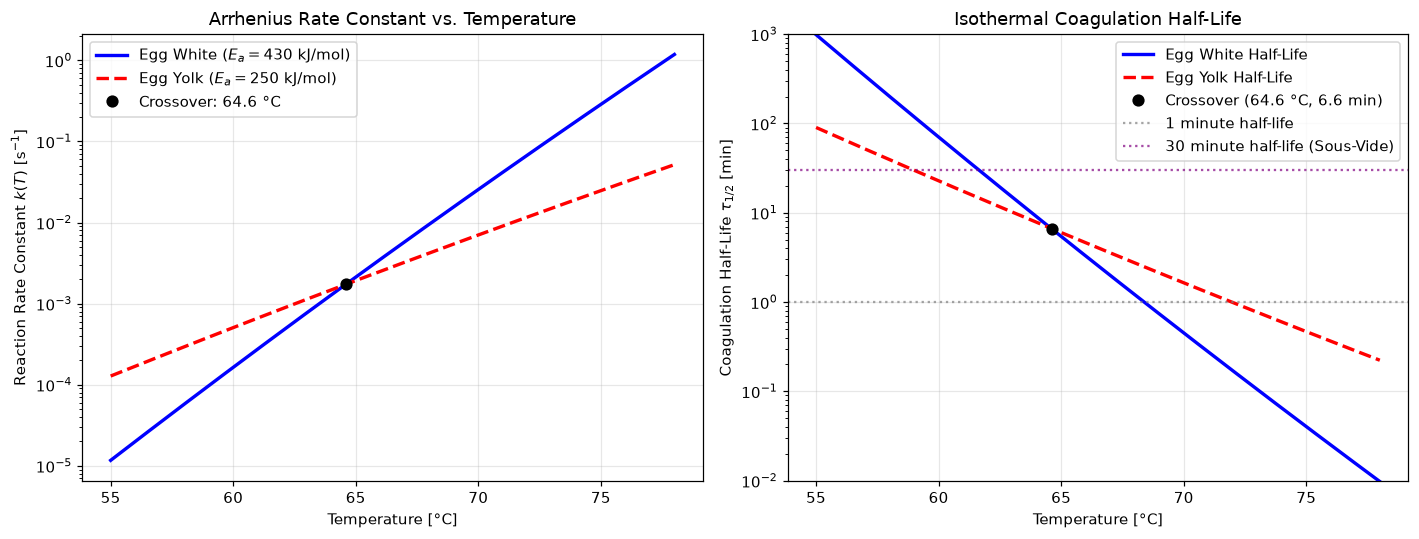

In [2]:
T_celsius = np.linspace(55, 78, 300)
T_kelvin = T_celsius + 273.15

k_white = WHITE_KINETICS.rate_constant(T_kelvin)
k_yolk = YOLK_KINETICS.rate_constant(T_kelvin)

t_half_white = WHITE_KINETICS.half_life(T_kelvin) / 60.0  # minutes
t_half_yolk = YOLK_KINETICS.half_life(T_kelvin) / 60.0    # minutes

# Find crossover temperature where k_white == k_yolk
idx_cross = np.argmin(np.abs(np.log(k_white) - np.log(k_yolk)))
T_cross_C = T_celsius[idx_cross]
t_half_cross_min = t_half_white[idx_cross]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Rate constant k(T)
ax = axes[0]
ax.semilogy(T_celsius, k_white, 'b-', lw=2.2, label=r'Egg White ($E_a = 430$ kJ/mol)')
ax.semilogy(T_celsius, k_yolk, 'r--', lw=2.2, label=r'Egg Yolk ($E_a = 250$ kJ/mol)')
ax.plot(T_cross_C, k_white[idx_cross], 'ko', markersize=7,
        label=f'Crossover: {T_cross_C:.1f} °C')
ax.set_xlabel('Temperature [°C]')
ax.set_ylabel(r'Reaction Rate Constant $k(T)$ [s$^{-1}$]')
ax.set_title('Arrhenius Rate Constant vs. Temperature')
ax.legend(loc='upper left')

# Right: Half-life tau_1/2(T)
ax = axes[1]
ax.semilogy(T_celsius, t_half_white, 'b-', lw=2.2, label='Egg White Half-Life')
ax.semilogy(T_celsius, t_half_yolk, 'r--', lw=2.2, label='Egg Yolk Half-Life')
ax.plot(T_cross_C, t_half_cross_min, 'ko', markersize=7,
        label=f'Crossover ({T_cross_C:.1f} °C, {t_half_cross_min:.1f} min)')
ax.axhline(1.0, color='gray', ls=':', alpha=0.7, label='1 minute half-life')
ax.axhline(30.0, color='purple', ls=':', alpha=0.7, label='30 minute half-life (Sous-Vide)')
ax.set_xlabel('Temperature [°C]')
ax.set_ylabel(r'Coagulation Half-Life $\tau_{1/2}$ [min]')
ax.set_title('Isothermal Coagulation Half-Life')
ax.set_ylim(1e-2, 1e3)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

## 2. Spatiotemporal Denaturation Field $\alpha(r, z, t)$ & Soft-Boiled Perfection Index

Next, we simulate a medium egg ($55\,\text{mm} \times 42\,\text{mm}$) starting at room temperature ($20\,^\circ\text{C}$) immersed in boiling water ($100\,^\circ\text{C}$) with convective shell transfer ($h = 2000\,\text{W/(m}^2\cdot\text{K)}$) and endothermic denaturation enthalpy.

By integrating $\alpha(\mathbf{x}, t)$ across the mesh subdomains, we obtain the axisymmetric volume-averaged conversion fractions $\bar{\alpha}_{\text{white}}(t)$ and $\bar{\alpha}_{\text{yolk}}(t)$, and define the **Soft-Boiled Perfection Index**:

$$\mathcal{I}(t) = \bar{\alpha}_{\text{white}}(t) \cdot \bigl(1 - \bar{\alpha}_{\text{yolk}}(t)\bigr)$$

which reaches its maximum when the egg white is maximally coagulated ($\bar{\alpha}_{\text{white}} \to 1$) while the yolk remains maximally runny ($\bar{\alpha}_{\text{yolk}} \to 0$).

In [3]:
mesh = create_egg_mesh()
material = {
    "yolk": egg_yolk_denaturation_properties,
    "white": egg_white_denaturation_properties,
}

solver_boil = HeatSolver(
    mesh=mesh,
    material=material,
    T_init=T_ROOM,
    T_boundary=T_BOILING,
    dt=1.0,
    h_conv=H_BOILING_SHELL,
)

print("Running 14-minute boiling simulation...")
solver_boil.run(t_end=840.0, progress=True)

kin_boil = compute_denaturation_history(mesh, solver_boil.times, solver_boil.temperatures)
t_min = np.array(solver_boil.times) / 60.0

idx_opt = int(np.argmax(kin_boil["perfection_index"]))
t_opt_min = t_min[idx_opt]
print(f"\nOptimal Soft-Boiled Time (max Perfection Index): {t_opt_min:.2f} min ({solver_boil.times[idx_opt]:.0f} s)")
print(f"  Volume-averaged White Coagulation: {kin_boil['alpha_white_avg'][idx_opt] * 100:.1f}%")
print(f"  Volume-averaged Yolk Coagulation:  {kin_boil['alpha_yolk_avg'][idx_opt] * 100:.1f}%")
print(f"  Peak Perfection Index I(t):        {kin_boil['perfection_index'][idx_opt]:.3f}")


Running 14-minute boiling simulation...


  t =   60.0 s (1.0 min)  T_center = 20.0 °C


  t =  120.0 s (2.0 min)  T_center = 20.0 °C


  t =  180.0 s (3.0 min)  T_center = 20.9 °C


  t =  240.0 s (4.0 min)  T_center = 23.7 °C


...

  t =  660.0 s (11.0 min)  T_center = 66.8 °C


  t =  720.0 s (12.0 min)  T_center = 71.7 °C


  t =  780.0 s (13.0 min)  T_center = 75.9 °C


  t =  840.0 s (14.0 min)  T_center = 79.6 °C



Optimal Soft-Boiled Time (max Perfection Index): 7.87 min (472 s)
  Volume-averaged White Coagulation: 94.2%
  Volume-averaged Yolk Coagulation:  4.4%
  Peak Perfection Index I(t):        0.901


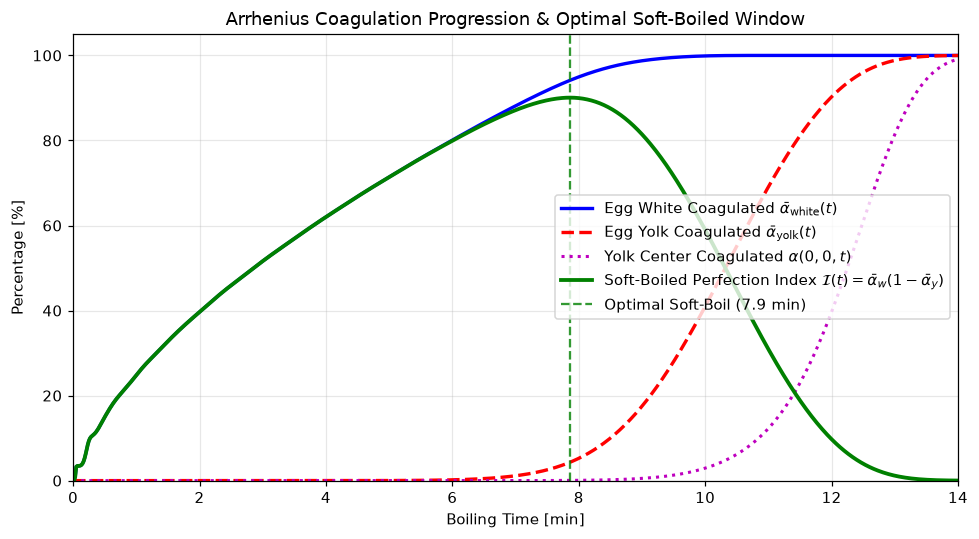

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(t_min, kin_boil["alpha_white_avg"] * 100, 'b-', lw=2.2,
        label=r'Egg White Coagulated $\bar{\alpha}_{\mathrm{white}}(t)$')
ax.plot(t_min, kin_boil["alpha_yolk_avg"] * 100, 'r--', lw=2.2,
        label=r'Egg Yolk Coagulated $\bar{\alpha}_{\mathrm{yolk}}(t)$')
ax.plot(t_min, kin_boil["alpha_center"] * 100, 'm:', lw=2.0,
        label=r'Yolk Center Coagulated $\alpha(0, 0, t)$')
ax.plot(t_min, kin_boil["perfection_index"] * 100, 'g-', lw=2.5,
        label=r'Soft-Boiled Perfection Index $\mathcal{I}(t) = \bar{\alpha}_w(1 - \bar{\alpha}_y)$')

ax.axvline(t_opt_min, color='green', ls='--', alpha=0.8,
           label=f'Optimal Soft-Boil ({t_opt_min:.1f} min)')

ax.set_xlabel('Boiling Time [min]')
ax.set_ylabel('Percentage [%]')
ax.set_title('Arrhenius Coagulation Progression & Optimal Soft-Boiled Window')
ax.set_xlim(0, 14)
ax.set_ylim(0, 105)
ax.legend(loc='center right')
plt.tight_layout()
plt.show()

### Spatial Coagulation Field $\alpha(r, z, t)$ vs. Naive Temperature Isotherms

Below we plot the spatial degree of protein denaturation $\alpha(r, z, t)$ at $t = 4, 6, 8, 10\,\text{min}$.
- **White solid line**: Naive $63\,^\circ\text{C}$ temperature isotherm.
- **Black dashed line**: $\alpha = 0.5$ ($50\%$ coagulated) kinetic front.
- **Yolk boundary**: Outlined in cyan.

Notice the **thermal-kinetic lag**: the $63\,^\circ\text{C}$ isotherm always leads the $\alpha = 0.5$ coagulation front inward because proteins require finite residence time at elevated temperature to denature.

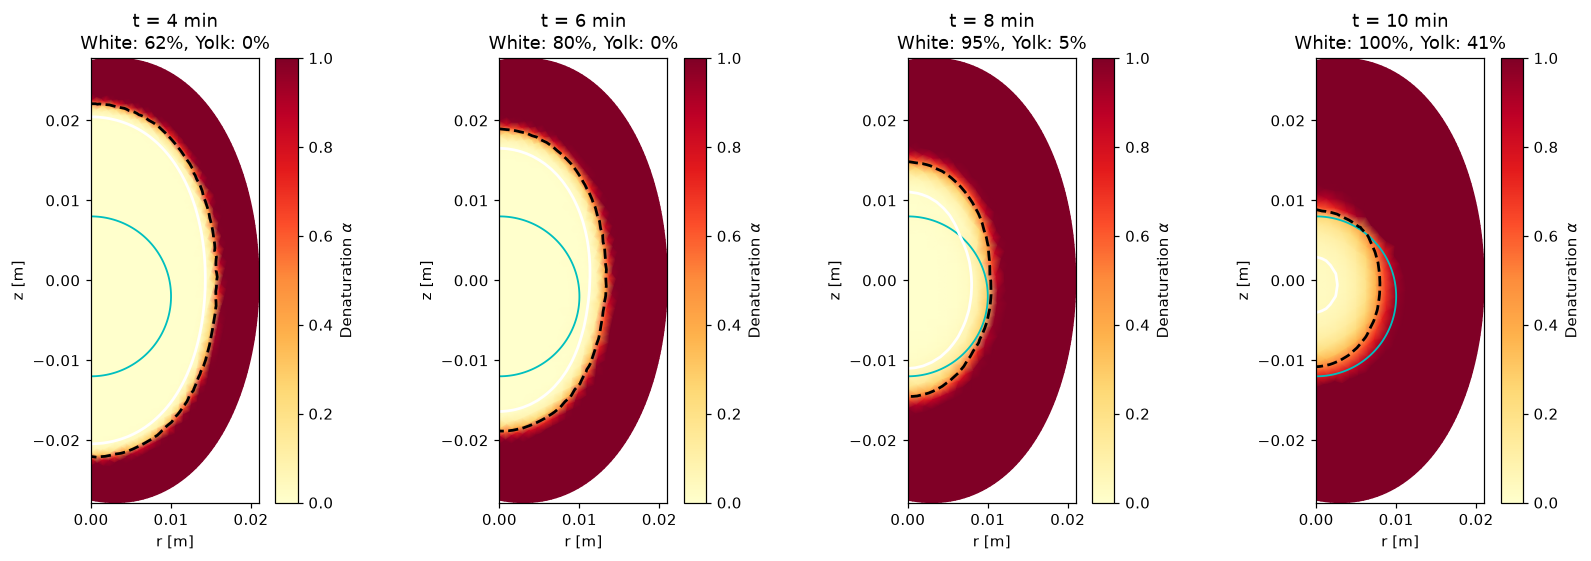

In [5]:
snapshot_mins = [4, 6, 8, 10]
fig, axes = plt.subplots(1, 4, figsize=(15, 5.2))

# Yolk boundary circle for overlay
theta = np.linspace(-np.pi / 2, np.pi / 2, 100)
r_yolk_bd = 0.010 * np.cos(theta)
z_yolk_bd = -0.002 + 0.010 * np.sin(theta)

for ax, tm in zip(axes, snapshot_mins):
    step = int(tm * 60)
    alpha_step = kin_boil["alpha"][step]
    T_step_C = solver_boil.temperatures[step] - 273.15

    tp = ax.tripcolor(
        mesh.p[0], mesh.p[1], mesh.t.T, alpha_step,
        shading='gouraud', cmap='YlOrRd', vmin=0.0, vmax=1.0,
    )
    fig.colorbar(tp, ax=ax, label=r'Denaturation $\alpha$')

    # Overlay yolk boundary
    ax.plot(r_yolk_bd, z_yolk_bd, 'c-', lw=1.2, label='Yolk boundary')

    # Overlay 63 °C isotherm (white) vs alpha = 0.5 front (black dashed)
    try:
        ax.tricontour(
            mesh.p[0], mesh.p[1], mesh.t.T, T_step_C,
            levels=[63.0], colors=['white'], linewidths=1.8, linestyles=['solid']
        )
    except ValueError:
        pass
    try:
        ax.tricontour(
            mesh.p[0], mesh.p[1], mesh.t.T, alpha_step,
            levels=[0.5], colors=['black'], linewidths=1.8, linestyles=['dashed']
        )
    except ValueError:
        pass

    ax.set_aspect('equal')
    ax.set_title(
        f't = {tm} min\n'
        f'White: {kin_boil["alpha_white_avg"][step]*100:.0f}%, '
        f'Yolk: {kin_boil["alpha_yolk_avg"][step]*100:.0f}%'
    )
    ax.set_xlabel('r [m]')
    ax.set_ylabel('z [m]')

plt.tight_layout()
plt.show()

## 3. Carryover Cooking vs. Ice-Bath Quenching

When an egg is removed from boiling water at the optimal soft-boiled time ($t = 6.3\,\text{min} = 380\,\text{s}$), the outer albumen is near $90\text{–}98\,^\circ\text{C}$ while the yolk center is around $45\text{–}50\,^\circ\text{C}$.

We compare two post-boil treatments over the next 6 minutes ($360\,\text{s}$):
1. **Counter-top Air Rest**: Ambient air at $T_\infty = 20\,^\circ\text{C}$ with natural convection $h_{\text{air}} = 15\,\text{W/(m}^2\cdot\text{K)}$.
2. **Ice-Water Bath Shock**: Ice bath at $T_\infty = 0\,^\circ\text{C}$ with vigorous water convection $h_{\text{ice}} = 1500\,\text{W/(m}^2\cdot\text{K)}$.

In [6]:
t_pull = 380.0   # 6.33 min boil
t_rest = 360.0   # 6.00 min post-boil

# 1. Counter-top air cooling
solver_air = HeatSolver(
    mesh, material, T_init=T_ROOM, T_boundary=T_BOILING, dt=1.0, h_conv=H_BOILING_SHELL
)
solver_air.run(t_end=t_pull, progress=False)
solver_air.set_boundary_conditions(T_boundary=T_ROOM, h_conv=15.0)
solver_air.run(t_end=t_pull + t_rest, progress=False)

# 2. Ice-water bath quenching
solver_ice = HeatSolver(
    mesh, material, T_init=T_ROOM, T_boundary=T_BOILING, dt=1.0, h_conv=H_BOILING_SHELL
)
solver_ice.run(t_end=t_pull, progress=False)
solver_ice.set_boundary_conditions(T_boundary=273.15, h_conv=1500.0)
solver_ice.run(t_end=t_pull + t_rest, progress=False)

kin_air = compute_denaturation_history(mesh, solver_air.times, solver_air.temperatures)
kin_ice = compute_denaturation_history(mesh, solver_ice.times, solver_ice.temperatures)

t_arr_min = np.array(solver_air.times) / 60.0
_, Tc_air = solver_air.center_temperature_history()
_, Tc_ice = solver_ice.center_temperature_history()

idx_pull = int(t_pull)
print(f"At removal from boiling water (t = {t_pull/60:.1f} min):")
print(f"  Yolk Coagulation:  {kin_air['alpha_yolk_avg'][idx_pull]*100:.1f}% | White Coagulation: {kin_air['alpha_white_avg'][idx_pull]*100:.1f}%")
print(f"After 6 min Counter-Top Air Rest:")
print(f"  Yolk Coagulation:  {kin_air['alpha_yolk_avg'][-1]*100:.1f}% (+{(kin_air['alpha_yolk_avg'][-1]-kin_air['alpha_yolk_avg'][idx_pull])*100:.1f}% carryover!)")
print(f"After 6 min Ice-Water Bath Quench:")
print(f"  Yolk Coagulation:  {kin_ice['alpha_yolk_avg'][-1]*100:.1f}% (+{(kin_ice['alpha_yolk_avg'][-1]-kin_ice['alpha_yolk_avg'][idx_pull])*100:.1f}% carryover)")

At removal from boiling water (t = 6.3 min):
  Yolk Coagulation:  0.4% | White Coagulation: 82.9%
After 6 min Counter-Top Air Rest:
  Yolk Coagulation:  74.1% (+73.7% carryover!)
After 6 min Ice-Water Bath Quench:
  Yolk Coagulation:  11.0% (+10.6% carryover)


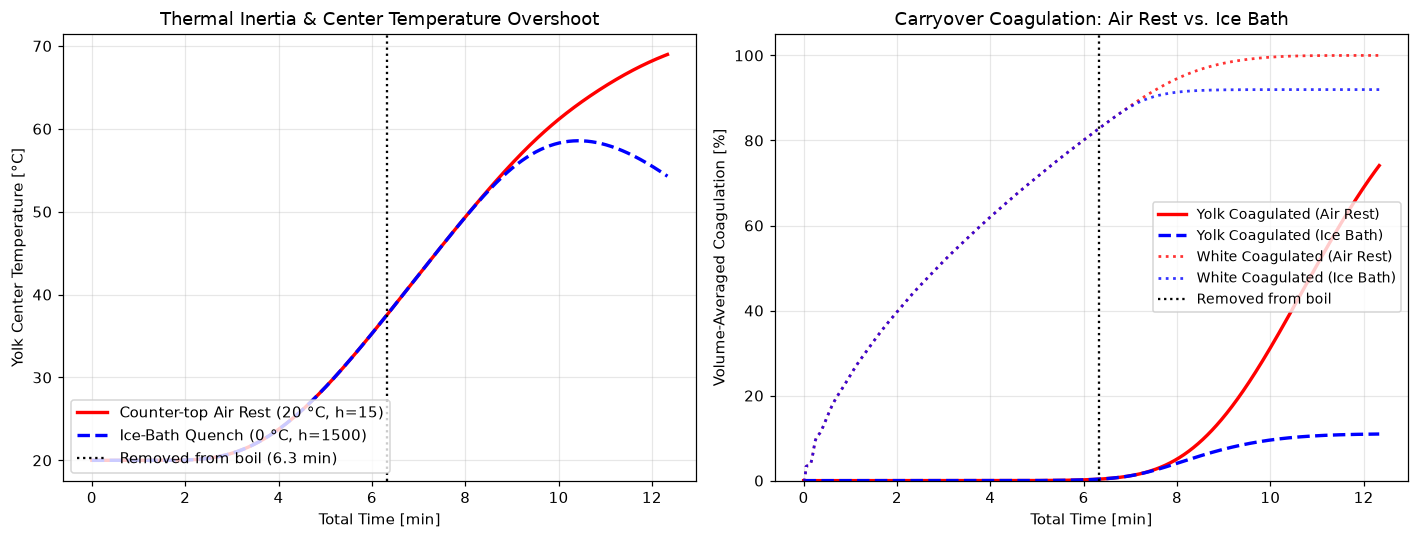

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Center temperature trajectory
ax = axes[0]
ax.plot(t_arr_min, Tc_air, 'r-', lw=2.2, label='Counter-top Air Rest (20 °C, h=15)')
ax.plot(t_arr_min, Tc_ice, 'b--', lw=2.2, label='Ice-Bath Quench (0 °C, h=1500)')
ax.axvline(t_pull / 60.0, color='k', ls=':', lw=1.5, label=f'Removed from boil ({t_pull/60:.1f} min)')
ax.set_xlabel('Total Time [min]')
ax.set_ylabel('Yolk Center Temperature [°C]')
ax.set_title('Thermal Inertia & Center Temperature Overshoot')
ax.legend(loc='lower left')

# Right: Volume-averaged yolk & white coagulation
ax = axes[1]
ax.plot(t_arr_min, kin_air["alpha_yolk_avg"] * 100, 'r-', lw=2.2, label='Yolk Coagulated (Air Rest)')
ax.plot(t_arr_min, kin_ice["alpha_yolk_avg"] * 100, 'b--', lw=2.2, label='Yolk Coagulated (Ice Bath)')
ax.plot(t_arr_min, kin_air["alpha_white_avg"] * 100, 'r:', lw=1.8, alpha=0.8, label='White Coagulated (Air Rest)')
ax.plot(t_arr_min, kin_ice["alpha_white_avg"] * 100, 'b:', lw=1.8, alpha=0.8, label='White Coagulated (Ice Bath)')
ax.axvline(t_pull / 60.0, color='k', ls=':', lw=1.5, label='Removed from boil')
ax.set_xlabel('Total Time [min]')
ax.set_ylabel('Volume-Averaged Coagulation [%]')
ax.set_title('Carryover Coagulation: Air Rest vs. Ice Bath')
ax.set_ylim(0, 105)
ax.legend(loc='center right', fontsize=9)

plt.tight_layout()
plt.show()

## 4. Low-Temperature Long-Time Cooking: Sous-Vide / Onsen Tamago ($63.5\,^\circ\text{C}$)

In a precision $63.5\,^\circ\text{C}$ water bath, the egg temperature **never reaches the $65\,^\circ\text{C}$ yolk threshold**. A threshold-based model therefore predicts $0\%$ yolk coagulation forever.

Using the Arrhenius kinetic model over a 45-minute immersion at $63.5\,^\circ\text{C}$, we see how the lower activation energy of yolk lipoproteins allows the yolk to surpass the white in coagulation at ~25 minutes, yielding the signature *Onsen Tamago* texture (custard-like yolk with silky, soft albumen).

In [8]:
T_SOUS_VIDE = 273.15 + 63.5  # 63.5 °C bath

solver_sv = HeatSolver(
    mesh=mesh,
    material=material,
    T_init=T_ROOM,
    T_boundary=T_SOUS_VIDE,
    dt=5.0,
    h_conv=H_BOILING_SHELL,
)

print("Running 45-minute Sous-Vide simulation at 63.5 °C (dt=5 s)...")
solver_sv.run(t_end=2700.0, progress=False)

kin_sv = compute_denaturation_history(mesh, solver_sv.times, solver_sv.temperatures)
t_sv_min = np.array(solver_sv.times) / 60.0
_, Tc_sv = solver_sv.center_temperature_history()

print(f"At t = 45 min in 63.5 °C Sous-Vide bath:")
print(f"  Center Temperature: {Tc_sv[-1]:.2f} °C (never reaches 65 °C threshold!)")
print(f"  Yolk Coagulation:   {kin_sv['alpha_yolk_avg'][-1]*100:.1f}% (custard-set)")
print(f"  White Coagulation:  {kin_sv['alpha_white_avg'][-1]*100:.1f}% (silky/soft-set)")

Running 45-minute Sous-Vide simulation at 63.5 °C (dt=5 s)...


At t = 45 min in 63.5 °C Sous-Vide bath:
  Center Temperature: 63.36 °C (never reaches 65 °C threshold!)
  Yolk Coagulation:   80.4% (custard-set)
  White Coagulation:  78.3% (silky/soft-set)


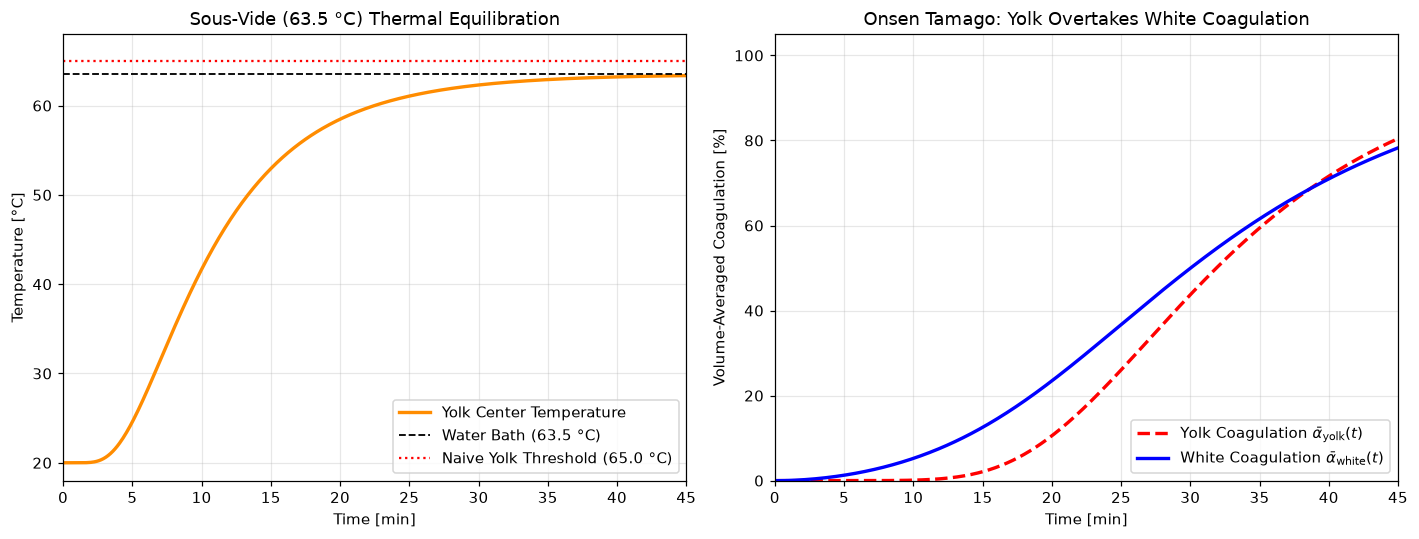

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Temperature equilibration
ax = axes[0]
ax.plot(t_sv_min, Tc_sv, 'darkorange', lw=2.2, label='Yolk Center Temperature')
ax.axhline(63.5, color='k', ls='--', lw=1.2, label='Water Bath (63.5 °C)')
ax.axhline(65.0, color='r', ls=':', lw=1.5, label='Naive Yolk Threshold (65.0 °C)')
ax.set_xlabel('Time [min]')
ax.set_ylabel('Temperature [°C]')
ax.set_title('Sous-Vide (63.5 °C) Thermal Equilibration')
ax.set_xlim(0, 45)
ax.set_ylim(18, 68)
ax.legend(loc='lower right')

# Right: Coagulation inversion
ax = axes[1]
ax.plot(t_sv_min, kin_sv["alpha_yolk_avg"] * 100, 'r--', lw=2.2,
        label=r'Yolk Coagulation $\bar{\alpha}_{\mathrm{yolk}}(t)$')
ax.plot(t_sv_min, kin_sv["alpha_white_avg"] * 100, 'b-', lw=2.2,
        label=r'White Coagulation $\bar{\alpha}_{\mathrm{white}}(t)$')
ax.set_xlabel('Time [min]')
ax.set_ylabel('Volume-Averaged Coagulation [%]')
ax.set_title('Onsen Tamago: Yolk Overtakes White Coagulation')
ax.set_xlim(0, 45)
ax.set_ylim(0, 105)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

## Summary

By coupling the axisymmetric transient heat equation with **Arrhenius protein denaturation kinetics**, we capture key culinary phenomena beyond reach of simple isotherm models:

| Phenomenon | Threshold Model ($63\,^\circ\text{C} / 65\,^\circ\text{C}$) | Arrhenius Kinetic FEM Model |
|---|---|---|
| **Boiling Soft-Boiled Window** | Wait until center reaches $63\,^\circ\text{C}$ (~10.3 min) | Optimal Perfection Index $\mathcal{I}(t)$ peaks at **7.9 min** ($94.2\%$ white set, $4.4\%$ yolk set) |
| **Carryover Cooking (Air Rest after 6.3 min boil)** | Ignored after removal from pot | Thermal inertia drives yolk coagulation from **$0.4\%$ to $74.1\%$** (+$73.7\%$ carryover!) |
| **Ice-Bath Quenching (after 6.3 min boil)** | Qualitative rule of thumb | Halts carryover rapidly, holding yolk coagulation at **$11.0\%$** |
| **Sous-Vide ($63.5\,^\circ\text{C}$, 45 min)** | Predicts $0\%$ yolk cooking ($T < 65\,^\circ\text{C}$) | Predicts **$80.4\%$ custard-set yolk** and **$78.3\%$ silky white** via kinetic crossover |